<a href="https://colab.research.google.com/github/rickycarrillo3/ML-Projects/blob/main/Demos/Decision_Trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Trees: Playing Twenty Questions with Data

Welcome back! So far in this series we have built two classifiers. In the logistic regression demo, we drew a single line and said "everything on this side is class 1". In the Gaussian Naive Bayes demo, we modeled each class as a Gaussian blob and asked which blob a new point most likely came from.

Today we try something that feels much more human. Have you ever played *Twenty Questions*? One person thinks of an object, and the other narrows it down with yes/no questions: "Is it alive?", "Is it bigger than a lunchbox?". A good player picks questions that cut down the possibilities as much as possible each time.

A **decision tree** is exactly this game, played on a dataset. Each question looks at a single feature, for example "Is the petal length $\le 2.5$ cm?", and sends the point left or right. After a few questions we reach a *leaf*, and we announce our guess.

But what makes a question *good*? Intuitively, a good question leaves us less uncertain than we were before. We will make "uncertainty" precise with a quantity called **entropy**. We will measure "how much a question helped" with **information gain**. If the $\log$ inside entropy looks familiar, that is no accident: it is closely related to the negative log-likelihood from our logistic regression demo.

**Today we will:**
- Define entropy and information gain, and compute them by hand on a tiny example.
- Write a function that tries every feature and threshold and picks the best question.
- Grow a full tree recursively from scratch with NumPy, using a maximum depth to know when to stop.
- Train it on the classic Iris flower dataset and print the learned tree as a list of questions.
- Experiment with the depth and see when our tree stops learning and starts memorizing.

Let's start playing!

## Mathematical foundations

### Our toy dataset

Let's keep things small enough to work out by hand. Here are 8 flowers, in the spirit of the Iris dataset. Each has two features and belongs to one of two classes:

| # | petal length $x_1$ (cm) | petal width $x_2$ (cm) | class |
|---|---|---|---|
| 1 | 1.4 | 0.2 | setosa |
| 2 | 1.3 | 0.3 | setosa |
| 3 | 1.5 | 0.6 | setosa |
| 4 | 1.6 | 1.1 | setosa |
| 5 | 3.9 | 0.7 | versicolor |
| 6 | 4.0 | 1.0 | versicolor |
| 7 | 4.5 | 1.3 | versicolor |
| 8 | 4.7 | 1.5 | versicolor |

Some notation we will use throughout:
- $n$ is the number of points.
- $x^{(i)} = (x^{(i)}_1, \dots, x^{(i)}_d)$ is the $i$-th feature vector, with $d$ features.
- $y^{(i)} \in \{1, \dots, K\}$ is its label, out of $K$ classes.

In the toy table, $n = 8$, $d = 2$ and $K = 2$.

A decision tree only asks one kind of question: **"Is $x_j \le t$?"** for some feature $j$ and threshold $t$. Glancing at the table, both of these look like reasonable first questions:

- **Question A:** "Is petal width $x_2 \le 0.85$?"
- **Question B:** "Is petal length $x_1 \le 2.75$?"

You can probably *see* that B is better. But a computer can't squint at a table. We need a number that scores each question, so let's build one.

### Measuring uncertainty: entropy

Let $S$ be the set of points that reach a node of the tree, and let $n_k$ be how many of them belong to class $k$. The class proportions are

$$p_k = \frac{n_k}{|S|} \qquad \text{(eq. 1)}$$

The **entropy** of the node measures how mixed those classes are:

$$H(S) = -\sum_{k=1}^{K} p_k \log_2 p_k \qquad \text{(eq. 2)}$$

We use the convention $0 \log_2 0 = 0$, so a class that does not appear contributes nothing.

Let's compute it at the root of our toy example. There are 4 setosa and 4 versicolor, so $p_1 = p_2 = \tfrac{1}{2}$:

$$H(\text{root}) = -\left(\tfrac{1}{2}\log_2 \tfrac{1}{2} + \tfrac{1}{2}\log_2 \tfrac{1}{2}\right) = -\left(-\tfrac{1}{2} - \tfrac{1}{2}\right) = 1 \text{ bit}$$

Two properties make entropy a good measure of uncertainty:
- A **pure** node, where every point has the same class, has $H = 0$: one $p_k$ is $1$ and $\log_2 1 = 0$. Nothing left to figure out.
- A **perfectly mixed** node, with $p_k = 1/K$ for every class, has the maximum entropy $H = \log_2 K$. That is $1$ bit for our toy example. For Iris, with $K = 3$, it is $\log_2 3 \approx 1.585$ bits.

The base of the logarithm only rescales $H$; it never changes which question wins. Base 2 just lets us read entropy in *bits*.

**Wait, haven't we seen this before?** Yes! Suppose that at this node we predict every point with the same probabilities $p_1, \dots, p_K$. The average negative log-likelihood from our logistic regression demo (in base 2) would then be

$$\frac{1}{|S|}\sum_{i \in S} -\log_2 p_{y^{(i)}} = \sum_{k=1}^{K} \frac{n_k}{|S|}\left(-\log_2 p_k\right) = H(S)$$

So entropy is just the average NLL of the best "constant guess" we can make at a node. Lowering entropy means our predictions are getting more confident and more correct.

### Asking a question: splitting a node

A question "Is $x_j \le t$?" splits the points at a node into two groups:

$$S_L(j, t) = \{\, i \in S : x^{(i)}_j \le t \,\}, \qquad S_R(j, t) = \{\, i \in S : x^{(i)}_j > t \,\} \qquad \text{(eq. 3)}$$

Points that answer "yes" go left; the rest go right.

### Scoring a question: information gain

After the split, we have two children, each with its own entropy. To get the uncertainty *after* the question, we average them, weighting each child by its share of the points:

$$H_{\text{children}}(S, j, t) = \frac{|S_L|}{|S|}\, H(S_L) + \frac{|S_R|}{|S|}\, H(S_R) \qquad \text{(eq. 4)}$$

Why weight them? Imagine a question that splits off a single point. That child is trivially pure, with $H = 0$, but we've learned almost nothing about the other seven points. The weights keep a tiny pure child from looking too good.

The **information gain** of a question is how much uncertainty it removes:

$$IG(S, j, t) = H(S) - H_{\text{children}}(S, j, t) \qquad \text{(eq. 5)}$$

The bigger the gain, the better the question.

### Working the toy example by hand

Let's score our two questions, plus one more for comparison.

**Question A: $x_2 \le 0.85$.**
- Left child: flowers 1, 2, 3 and 5, so 3 setosa and 1 versicolor:
$$H(S_L) = -\left(\tfrac{3}{4}\log_2\tfrac{3}{4} + \tfrac{1}{4}\log_2\tfrac{1}{4}\right) \approx 0.311 + 0.5 = 0.811$$
- Right child: flowers 4, 6, 7 and 8, so 1 setosa and 3 versicolor. By symmetry, $H(S_R) \approx 0.811$.
- Weighted child entropy: $\tfrac{4}{8}(0.811) + \tfrac{4}{8}(0.811) = 0.811$.
- Gain: $IG = 1 - 0.811 = 0.189$ bits.

**Question B: $x_1 \le 2.75$.**
- Left child: flowers 1 to 4, all setosa, so $H(S_L) = 0$.
- Right child: flowers 5 to 8, all versicolor, so $H(S_R) = 0$.
- Gain: $IG = 1 - 0 = 1$ bit, the maximum possible here.

**Bonus, Question C: $x_2 \le 0.65$.** This uses the same feature as A, but a different threshold.
- Left child: flowers 1, 2 and 3, all setosa, so $H(S_L) = 0$.
- Right child: flower 4 plus the 4 versicolor, so $p = (\tfrac{1}{5}, \tfrac{4}{5})$:
$$H(S_R) = -\left(\tfrac{1}{5}\log_2\tfrac{1}{5} + \tfrac{4}{5}\log_2\tfrac{4}{5}\right) \approx 0.722$$
- Weighted child entropy: $\tfrac{3}{8}(0) + \tfrac{5}{8}(0.722) \approx 0.451$.
- Gain: $IG \approx 1 - 0.451 = 0.549$ bits.

| Question | $H(S_L)$ | $H(S_R)$ | $H_{\text{children}}$ | $IG$ |
|---|---|---|---|---|
| A: $x_2 \le 0.85$ | 0.811 | 0.811 | 0.811 | 0.189 |
| B: $x_1 \le 2.75$ | 0 | 0 | 0 | **1.000** |
| C: $x_2 \le 0.65$ | 0 | 0.722 | 0.451 | 0.549 |

Our intuition is now a number. Question B wins. Notice also that A and C ask about the *same feature* and still score very differently, so the threshold matters as much as the feature.

### Which thresholds should we try?

There are infinitely many values of $t$, but only a few distinct splits. Any $t$ between two neighboring data values sends exactly the same points left and right.

So for feature $j$, we sort its distinct values $v_1 < v_2 < \dots < v_m$ and only try the midpoints:

$$t_r = \frac{v_r + v_{r+1}}{2}, \qquad r = 1, \dots, m - 1 \qquad \text{(eq. 6)}$$

For petal length in our toy table, the sorted values are $1.3, 1.4, 1.5, 1.6, 3.9, 4.0, 4.5, 4.7$. The midpoint between $1.6$ and $3.9$ is exactly the $2.75$ from Question B.

Each feature has at most $n - 1$ candidate thresholds, so there are at most $d(n-1)$ questions to score. The best question is the one with the highest gain:

$$(j^*, t^*) = \arg\max_{j,\; t} \; IG(S, j, t) \qquad \text{(eq. 7)}$$

This is a plain brute-force search. With $d = 2$ and $n = 8$, it is just 14 candidates; with Iris ($d = 4$, $n = 150$), still only a few hundred.

### Growing the tree: recursion and stopping

Once we have the best question for a node, we apply the same procedure to each child, and then to their children, and so on. That's the whole algorithm:

1. Given the points $S$ at the current node, check the stopping rules below. If any applies, make this node a **leaf**.
2. Otherwise, find $(j^*, t^*)$ with eq. 7.
3. Split $S$ into $S_L$ and $S_R$ with eq. 3, and build each child by going back to step 1.

We stop splitting a node when:
- it is **pure** ($H(S) = 0$), so there is nothing left to learn;
- it has reached the **maximum depth** `max_depth`, a hyperparameter we choose;
- **no question has positive gain** ($IG \le 0$ for every candidate), for example when all points share the same feature values but have different labels.

A leaf predicts the **majority class** of the training points that reached it:

$$\hat{y}_{\text{leaf}} = \arg\max_{k} \; p_k \qquad \text{(eq. 8)}$$

The proportions $p_k$ themselves can also serve as predicted class probabilities.

In our toy example, the root asks Question B, and both children are pure. So the tree stops after a single question, at depth 1:

```
Is petal length <= 2.75?
├── yes -> setosa      (4 setosa, 0 versicolor)
└── no  -> versicolor  (0 setosa, 4 versicolor)
```

### Making a prediction

To classify a new point, we start at the root, answer each question, follow the matching branch, and return the leaf's class from eq. 8.

Take a new flower with $x_1 = 1.8$ and $x_2 = 0.9$. Our tree asks whether $1.8 \le 2.75$. Yes, so we predict setosa.

If we had used Question A instead, this flower would have gone right, since $0.9 > 0.85$. That leaf is mostly versicolor, so it would have been labeled versicolor. Higher gain really does translate into better decisions.

### One last remark: the tree is greedy

At each node, we pick the question that is best *right now* (eq. 7), without looking ahead to see whether a worse question today could enable better questions later. Finding the truly optimal tree is computationally very hard, so practically every decision tree algorithm is greedy like ours.

This also explains why `max_depth` matters so much. With no limit, the tree keeps asking questions until every leaf is pure, even if that means memorizing noise in the training data. We will see that happen in the experiments at the end.

## Questions for you

Before we start coding, try these on your own. Pen and paper is fine! The answers are hidden, so peek only after you have given each one a real try.

**Question 1.** The full Iris dataset has 150 flowers: 50 of each of the 3 species. What is the entropy (eq. 2) of the root node? It turns out that the question "is petal length $\le 2.45$ cm?" sends all 50 *setosa* flowers left and the other 100 flowers (50 *versicolor*, 50 *virginica*) right. What is the information gain (eq. 3) of this question?

<details><summary>Show answer</summary>

At the root, $p = (\tfrac{1}{3}, \tfrac{1}{3}, \tfrac{1}{3})$, so

$$H(S) = -3 \cdot \tfrac{1}{3} \log_2 \tfrac{1}{3} = \log_2 3 \approx 1.585.$$

This is the largest entropy possible with 3 classes. The labels are as mixed as they can be.

The two children after the split:
- Left: 50 setosa. This node is pure, so $H(S_{\text{left}}) = 0$.
- Right: 50 versicolor and 50 virginica. That is a 50/50 split, so $H(S_{\text{right}}) = 1$.

The weighted child entropy is $\tfrac{50}{150} \cdot 0 + \tfrac{100}{150} \cdot 1 \approx 0.667$. So

$$IG \approx 1.585 - 0.667 = 0.918 \text{ bits}.$$

One question removes more than half of our uncertainty. Keep this number in mind: our code should find this split at the root.

</details>

**Question 2.** Suppose we measured petal length in millimetres instead of centimetres, so every value gets multiplied by 10. Would the learned tree change? How does this compare with logistic regression trained by gradient descent?

<details><summary>Show answer</summary>

The tree would ask exactly the same questions. Only the threshold numbers change: "is petal length $\le 2.45$ cm?" simply becomes "$\le 24.5$ mm?".

Why? A split only depends on the *order* of the values. Multiplying by 10 keeps the order, so the candidate splits from eq. 4 group the points the same way. Every information gain therefore stays the same. In fact, any strictly increasing transformation of a feature, even taking its logarithm, leaves the tree's splits unchanged.

Logistic regression is different. Its gradient depends directly on the feature values. In that demo, we saw that large feature values forced us to use a tiny learning rate to keep the loss from blowing up. Decision trees do not care about feature scale, which is one reason they are pleasant to use on raw data.

</details>

**Question 3.** Imagine we set no maximum depth and let `min_samples_split = 2`. What training accuracy would the tree reach? Is that good news?

<details><summary>Show answer</summary>

The tree keeps splitting until every leaf is pure, or until it is stuck. So it reaches **100% training accuracy**.

There is one exception. If two training points have *identical* features but different labels, no question can separate them. That leaf stays mixed, and the best gain there is $0$.

Is that good news? Not necessarily. On noisy data, some leaves end up containing a single unusual training point. The tree has *memorized* that point instead of learning a general pattern, and it will often do worse on new test points. This is called **overfitting**, and it is exactly what we will watch for when we vary `max_depth`.

</details>

**Question 4.** Take two features and the classes "above the line $x_2 = x_1$" versus "below it". Logistic regression handles this with a single line. How would a decision tree handle it, and what happens as we allow more depth?

<details><summary>Show answer</summary>

Every split is a cut parallel to one of the axes, so the tree cannot draw a diagonal line directly. Instead, it approximates the diagonal with a **staircase** of horizontal and vertical cuts.

- A shallow tree gives a few big, coarse steps and misclassifies points near the line.
- A deeper tree gives more, smaller steps that hug the diagonal more closely, but it needs many more questions to do it.

The lesson: no classifier is best everywhere. Logistic regression is great when the true boundary is a straight line at any angle. Trees shine when the boundary is made of axis-aligned pieces, or when it is too irregular for a single line.

</details>

**Question 5.** Consider an "XOR" dataset. Points are spread evenly over the square $[-1, 1]^2$, and a point is class 1 when exactly one of $x_1, x_2$ is positive (top-left and bottom-right quarters), and class 0 otherwise. A depth-2 tree can classify this perfectly. Can you see how? Now, what will our *greedy* procedure think of the root question "is $x_1 \le 0$?"

<details><summary>Show answer</summary>

**A perfect depth-2 tree.** First ask "is $x_1 \le 0$?". Then, in *both* children, ask "is $x_2 \le 0$?". Each of the four leaves is one quarter of the square, and each quarter is pure.

**What greedy sees at the root.** After "is $x_1 \le 0$?", each child still contains half class 0 and half class 1. Both children have entropy about $1$, the same as the root, so the information gain is about $0$.

The same is true for every other single cut. No first question looks useful on its own, even though it sets up a perfect second question. With real, finite data the gains will be small rather than exactly $0$. The greedy root may then pick a nearly arbitrary threshold. If a gain is exactly $0$, it stops right there.

This is the price of being greedy (Step 6): a node picks what looks best *now*, without planning ahead. It usually works well, but XOR-like patterns are the classic case where it struggles.

</details>

## Implementation from scratch

Time to turn the math into code! We will build the tree in small pieces, following the steps from the math section:

1. `entropy` (eq. 2)
2. `information_gain` (eq. 3)
3. `candidate_thresholds` (eq. 4)
4. `find_best_split` (eq. 5)
5. `build_tree`, which grows the tree recursively, with leaves predicting a majority vote (eq. 6)
6. `predict` and `print_tree`, so we can use the tree and read it

After each piece, we check it against the numbers we computed by hand. That way, when the tree finally grows, we can trust every part of it.

We only need NumPy, plus matplotlib for one small plot. No scikit-learn model in sight: the tree is all ours.

In [1]:
# NumPy does the number crunching: counting labels, logs, boolean masks
import numpy as np
# math gives us log2 for the plain-Python versions shown in the comments
import math
# random is only imported so we can seed it, keeping the notebook reproducible
import random
# matplotlib for plots
import matplotlib.pyplot as plt

# ==== Hyperparameters (feel free to change!) ====
seed = 42  # @param {type:"integer"} random seed for reproducibility, any integer works
# ================================================

# Fix the random seeds so every run gives the same results
np.random.seed(seed)
random.seed(seed)

### Entropy

Let's start with the heart of it all: how mixed is a node? We count how many points of each class the node holds (the $n_k$). We turn the counts into proportions $p_k$ (eq. 1) and plug them into eq. 2.

Remember the convention $0 \cdot \log_2 0 = 0$. In code we get it for free: `np.unique` only returns the classes that actually appear in the node, so a missing class is never fed to the logarithm.

In [2]:
def entropy(labels):
    """
    Entropy H(S) of a node, measured in bits (eq. 2).

    labels : 1D array with the integer class labels of the points in the node.
    """
    labels = np.asarray(labels)
    # Number of points in the node, |S|
    n = len(labels)
    # An empty node holds no uncertainty (this only shows up in edge cases)
    if n == 0:
        return 0.0
    # Count each class that actually appears: these are the n_k.
    # Classes with zero count are skipped, which is our 0 * log2(0) = 0 convention.
    _, counts = np.unique(labels, return_counts=True)
    # Only one class present means a pure node: entropy is exactly 0
    if len(counts) == 1:
        return 0.0
    # Proportions p_k = n_k / |S| (eq. 1)
    proportions = counts / n
    # H(S) = -sum_k p_k * log2(p_k) (eq. 2)
    # Plain-Python version:
    # h = 0.0
    # for p in proportions:
    #     h -= p * math.log2(p)
    # return h
    return float(-np.sum(proportions * np.log2(proportions)))

Let's check `entropy` against the values we worked out by hand. We will also plot the two-class entropy as the share of class 1 goes from $0$ to $1$. We expect $0$ at both ends (pure nodes) and a peak of $1$ bit in the middle (a 50/50 node).

Pure node            H = 0.000   (expected 0.000)
50/50 node           H = 1.000   (expected 1.000)
75/25 node           H = 0.811   (expected 0.811)
Three equal classes  H = 1.585   (expected 1.585)


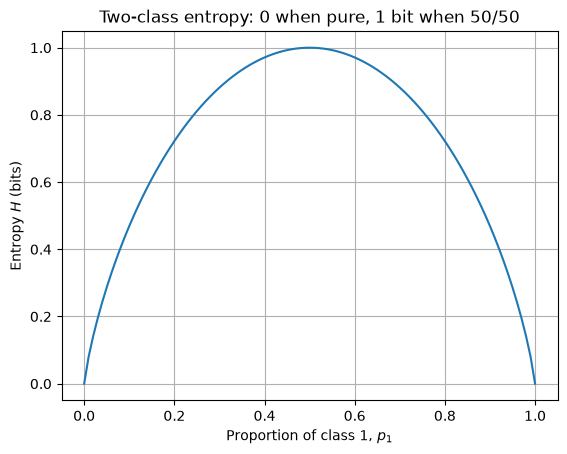

In [3]:
# ==== Hyperparameters (feel free to change!) ====
n_curve_points = 100  # @param {type:"slider", min:10, max:500} points per node used to draw the curve, more = smoother
# ================================================

# Pure node, p = (1, 0): expect 0 bits
print(f"Pure node            H = {entropy([0, 0, 0, 0]):.3f}   (expected 0.000)")
# 50/50 node: expect exactly 1 bit
print(f"50/50 node           H = {entropy([0, 1, 0, 1]):.3f}   (expected 1.000)")
# 75/25 node: expect about 0.811 bits
print(f"75/25 node           H = {entropy([0, 0, 0, 1]):.3f}   (expected 0.811)")
# Iris-like root with 50 points of each of 3 classes: expect log2(3), about 1.585 (Question 1)
iris_like_root = np.array([0] * 50 + [1] * 50 + [2] * 50)
print(f"Three equal classes  H = {entropy(iris_like_root):.3f}   (expected 1.585)")

# Build nodes with 0, 1, 2, ..., n_curve_points points of class 1 and record their entropy
p_values = []
h_values = []
for n_ones in range(n_curve_points + 1):
    # A node with n_ones points of class 1 and the rest of class 0
    node_labels = np.array([1] * n_ones + [0] * (n_curve_points - n_ones))
    # Proportion of class 1 in this node (eq. 1)
    p_values.append(n_ones / n_curve_points)
    # Its entropy (eq. 2)
    h_values.append(entropy(node_labels))

# Plot entropy against the proportion of class 1
plt.plot(p_values, h_values)
plt.xlabel('Proportion of class 1, $p_1$')
plt.ylabel('Entropy $H$ (bits)')
plt.title('Two-class entropy: 0 when pure, 1 bit when 50/50')
plt.grid(True)
plt.show()

Sweet! All four values match, and the curve has exactly the hill shape we wanted.

### Information gain

Next: how much did a question help? Eq. 3 says to take the parent's entropy and subtract the children's entropies, each weighted by the child's share of the points. Once `entropy` exists, this is just a few lines.

As a check, we reproduce Question 1. The split "petal length $\le 2.45$" sends 50 setosa left and 50 versicolor plus 50 virginica right. We only need the labels, so we don't even have to load Iris yet.

In [4]:
def information_gain(parent_labels, left_labels, right_labels):
    """
    Information gain of splitting a node into a left and a right child (eq. 3).
    """
    # Sizes |S|, |S_left| and |S_right|
    n = len(parent_labels)
    n_left = len(left_labels)
    n_right = len(right_labels)
    # Uncertainty before the question: H(S)
    h_before = entropy(parent_labels)
    # Uncertainty after: children's entropies weighted by their share of points (eq. 3)
    h_after = (n_left / n) * entropy(left_labels) + (n_right / n) * entropy(right_labels)
    # Information gain = parent entropy - weighted child entropy (eq. 3)
    return h_before - h_after


# Check with Question 1: the root split that isolates setosa
left_q1 = np.array([0] * 50)             # 50 setosa go left (pure)
right_q1 = np.array([1] * 50 + [2] * 50)  # 50 versicolor + 50 virginica go right
print(f"IG of the setosa split = {information_gain(iris_like_root, left_q1, right_q1):.3f} bits   (expected 0.918)")

IG of the setosa split = 0.918 bits   (expected 0.918)


### Candidate thresholds

We can't try infinitely many thresholds, and we don't need to. Only the gaps between the values that actually appear in the node matter. So we sort the distinct values and take the midpoint of each neighbouring pair (eq. 4).

One nice side effect: if a feature has the same value for every point in the node, there are no midpoints at all. The function returns an empty list, which tells us this feature cannot split the node.

In [5]:
def candidate_thresholds(feature_values):
    """
    Midpoints between neighbouring distinct values of one feature (eq. 4).

    feature_values : 1D array with the values of feature j for the points in the node.
    """
    # Sorted distinct values v_1 < v_2 < ... < v_m (np.unique sorts for us)
    values = np.unique(feature_values)
    # Midpoints t_r = (v_r + v_{r+1}) / 2 for r = 1, ..., m-1 (eq. 4)
    # Plain-Python version:
    # thresholds = []
    # for r in range(len(values) - 1):
    #     thresholds.append((values[r] + values[r + 1]) / 2)
    # return thresholds
    # If m = 1 (all values equal), this slice is empty: no possible split
    return (values[:-1] + values[1:]) / 2


# Quick check: the distinct values 1, 2, 2, 4 give midpoints 1.5 and 3.0
print(candidate_thresholds(np.array([4.0, 1.0, 2.0, 2.0])))

[1.5 3. ]


### Reproducing our hand-made table

Now we have every ingredient needed to rebuild the table from the math section. We take the 8 toy points and loop over every candidate threshold. For each one we ask "is $x \le t$?" and compute the entropies and the information gain.

If our functions are right, $t = 3.5$ should come out on top with $IG \approx 0.549$.

In [6]:
# The toy dataset from the math section: one feature x, two classes
x_toy = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
y_toy = np.array([0, 0, 0, 1, 1, 0, 1, 1])

# Entropy before asking anything: 4 zeros and 4 ones, so we expect 1 bit
print(f"Parent entropy H(S) = {entropy(y_toy):.3f}")
print()

# Table header
print(f"{'t':>4} | {'left':>8} | {'right':>8} | {'H(left)':>7} | {'H(right)':>8} | {'weighted':>8} | {'IG':>5}")
print('-' * 68)

# Try every candidate threshold (eq. 4)
for t in candidate_thresholds(x_toy):
    # Ask the question "is x <= t?" for every point at once (True = goes left)
    left_mask = x_toy <= t
    # Labels that end up in each child
    left_labels = y_toy[left_mask]
    right_labels = y_toy[~left_mask]
    # Each child's entropy (eq. 2)
    h_left = entropy(left_labels)
    h_right = entropy(right_labels)
    # Weighted child entropy: the 'after' part of eq. 3
    weighted = (len(left_labels) / len(y_toy)) * h_left + (len(right_labels) / len(y_toy)) * h_right
    # Information gain (eq. 3)
    gain = information_gain(y_toy, left_labels, right_labels)
    # Print the labels as compact strings like '000' so the row is easy to read
    left_str = ''.join(str(v) for v in left_labels)
    right_str = ''.join(str(v) for v in right_labels)
    print(f"{t:>4.1f} | {left_str:>8} | {right_str:>8} | {h_left:>7.3f} | {h_right:>8.3f} | {weighted:>8.3f} | {gain:>5.3f}")

Parent entropy H(S) = 1.000

   t |     left |    right | H(left) | H(right) | weighted |    IG
--------------------------------------------------------------------
 1.5 |        0 |  0011011 |   0.000 |    0.985 |    0.862 | 0.138
 2.5 |       00 |   011011 |   0.000 |    0.918 |    0.689 | 0.311
 3.5 |      000 |    11011 |   0.000 |    0.722 |    0.451 | 0.549
 4.5 |     0001 |     1011 |   0.811 |    0.811 |    0.811 | 0.189
 5.5 |    00011 |      011 |   0.971 |    0.918 |    0.951 | 0.049
 6.5 |   000110 |       11 |   0.918 |    0.000 |    0.689 | 0.311
 7.5 |  0001101 |        1 |   0.985 |    0.000 |    0.862 | 0.138


Nice, every row matches the table we computed by hand!

### Picking the best question

The loop we just wrote is really most of eq. 5 already. `find_best_split` wraps it in a second loop over **all** features. It remembers the (feature, threshold) pair with the largest gain.

We use a strict `>` when comparing gains, so if two questions tie, we keep the first one we found. If no feature can split the node at all (every feature is constant), we return `None` for the feature. The tree-building code will then turn the node into a leaf.

In [7]:
def find_best_split(X, y):
    """
    Brute-force search for the best question "is x_j <= t?" (eq. 5).

    X : array of shape (n, d) with the features of the points in the node
    y : array of shape (n,) with their labels

    Returns (best_feature, best_threshold, best_gain).
    best_feature is None if no feature can split the node.
    """
    # Number of features d
    n_features = X.shape[1]
    # Nothing found yet; any real gain (which is always >= 0) beats -1
    best_feature = None
    best_threshold = None
    best_gain = -1.0
    # Try every feature j ...
    for j in range(n_features):
        # Column j: the value of feature j for every point in the node
        feature_values = X[:, j]
        # ... and every candidate threshold for that feature (eq. 4)
        for t in candidate_thresholds(feature_values):
            # Ask "is x_j <= t?" for all points at once (True = goes left)
            left_mask = feature_values <= t
            # How much does this question reduce uncertainty? (eq. 3)
            gain = information_gain(y, y[left_mask], y[~left_mask])
            # Keep it only if strictly better, so ties keep the first question found (eq. 5)
            if gain > best_gain:
                best_feature = j
                best_threshold = t
                best_gain = gain
    return best_feature, best_threshold, best_gain


# Check on the toy data: X must be a 2D array of shape (n, d), here d = 1
feature, threshold, gain = find_best_split(x_toy.reshape(-1, 1), y_toy)
print(f"Best question: is x[{feature}] <= {threshold}?  IG = {gain:.3f}   (expected x[0] <= 3.5, IG = 0.549)")

Best question: is x[0] <= 3.5?  IG = 0.549   (expected x[0] <= 3.5, IG = 0.549)


### Growing the tree

We now know how to pick one question. A tree is just this, applied over and over (Step 6):

- `make_leaf` builds a leaf. It stores the class proportions $p_k$ (eq. 1) and predicts the majority class (eq. 6).
- `build_tree` is recursive. It first checks the stopping rules. If none applies, it finds the best split, divides the points, and calls itself on each child, one level deeper.

We store each node as a plain Python dictionary, so we can open it up and look inside at any time.

The stopping rules are the ones from the math section, with one small twist. Instead of stopping only when the best gain is exactly $0$, we stop when it is at most `min_gain`. With a tiny value like `1e-6`, this behaves like the "no question helps" rule, while ignoring rounding noise in floating-point arithmetic. Larger values make the tree more picky about which questions are worth asking.

We count depth from $0$ at the root. So `max_depth = 3` means at most 3 questions on any path from the root to a leaf.

The hyperparameter block at the top of the next cell sets the *default* stopping rules used by `fit_tree`. Later cells can override them by passing their own values.

In [8]:
# ==== Hyperparameters (feel free to change!) ====
default_max_depth = 3          # @param {type:"slider", min:1, max:10} default max questions on any root-to-leaf path
default_min_samples_split = 2  # @param {type:"slider", min:2, max:20} default: nodes with fewer points than this become leaves
default_min_gain = 1e-6        # @param {type:"number"} default: a split must gain more than this many bits, try 0.0-0.3
# ================================================

def make_leaf(y, n_classes):
    """
    Build a leaf that predicts by majority vote (eq. 6).
    """
    # n_k for every class, including classes with zero points in this leaf
    counts = np.bincount(y, minlength=n_classes)
    # Proportions p_k = n_k / |S| (eq. 1), which we keep as the leaf's confidence
    proportions = counts / len(y)
    # Majority vote: y_hat = argmax_k p_k (eq. 6); on ties, argmax picks the smallest class index
    prediction = int(np.argmax(proportions))
    return {'leaf': True, 'prediction': prediction, 'proportions': proportions, 'n_samples': len(y)}


def build_tree(X, y, depth, max_depth, min_samples_split, min_gain, n_classes):
    """
    Recursively grow a decision tree (Step 6).

    depth : how many questions were asked to reach this node (0 at the root)
    """
    # Stopping rule 1: the node is pure (H(S) = 0), nothing left to learn
    if entropy(y) == 0.0:
        return make_leaf(y, n_classes)
    # Stopping rule 2: we have reached the maximum depth we allow
    if depth >= max_depth:
        return make_leaf(y, n_classes)
    # Stopping rule 3: too few points to be worth splitting
    if len(y) < min_samples_split:
        return make_leaf(y, n_classes)

    # Find the best question for this node (eq. 5)
    feature, threshold, gain = find_best_split(X, y)

    # Stopping rule 4: no question can split the node, or the best one barely helps
    if feature is None or gain <= min_gain:
        return make_leaf(y, n_classes)

    # Split the points: "yes" (x_j <= t) goes left, "no" goes right
    left_mask = X[:, feature] <= threshold
    # Grow each child recursively, one level deeper
    left_child = build_tree(X[left_mask], y[left_mask], depth + 1,
                            max_depth, min_samples_split, min_gain, n_classes)
    right_child = build_tree(X[~left_mask], y[~left_mask], depth + 1,
                             max_depth, min_samples_split, min_gain, n_classes)

    # An internal node remembers its question, its gain and its two children
    return {'leaf': False, 'feature': feature, 'threshold': threshold, 'gain': gain,
            'n_samples': len(y), 'left': left_child, 'right': right_child}


def fit_tree(X, y, max_depth=default_max_depth, min_samples_split=default_min_samples_split,
             min_gain=default_min_gain):
    """
    Convenience wrapper: tidy up the inputs, then grow the tree from the root.
    The stopping rules default to the hyperparameter block above.
    """
    # Features as floats; a 1D array means a single feature, so make it a column of shape (n, 1)
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    # Labels as integers 0, 1, ..., K-1 (np.bincount in make_leaf needs this)
    y = np.asarray(y).astype(int)
    # Number of classes K, so every leaf reports a proportion for every class
    n_classes = int(y.max()) + 1
    # Start the recursion at the root, depth 0, with all training points
    return build_tree(X, y, 0, max_depth, min_samples_split, min_gain, n_classes)

### Using the tree

To classify a new point, we start at the root and keep answering questions until we land in a leaf (Step 7). Since every question sends us one level down, a simple `while` loop does the job.

We also add a few small helpers:
- `compute_accuracy`, the fraction of correct predictions, just like in our earlier demos.
- `tree_depth` and `count_leaves`, which tell us how big a tree actually grew. These will be handy when we experiment with `max_depth`.

At the end of the cell, we run a quick check. We grow a one-question tree (a "stump") on the toy data. It should ask "is $x \le 3.5$?" and get 7 of the 8 points right.

In [9]:
# ==== Hyperparameters (feel free to change!) ====
check_max_depth = 1  # @param {type:"slider", min:1, max:5} depth of the quick-check tree, 1 = a single question (a "stump")
# ================================================

def predict_one(tree, x):
    """
    Walk one point down the tree and return the leaf's prediction (Step 7).
    """
    # Start at the root
    node = tree
    # Keep asking questions until we reach a leaf
    while not node['leaf']:
        # Answer this node's question: is x_j <= t?
        if x[node['feature']] <= node['threshold']:
            node = node['left']   # yes -> go left
        else:
            node = node['right']  # no -> go right
    # The leaf's majority vote is our answer (eq. 6)
    return node['prediction']


def predict(tree, X):
    """
    Predict a class for every row of X.
    """
    # Same input tidying as in fit_tree, so 1D inputs also work
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    # Walk each point down the tree, one at a time
    return np.array([predict_one(tree, x) for x in X])


def compute_accuracy(y_true, y_pred):
    """
    Fraction of points whose predicted class matches the true class.
    """
    # Plain-Python version:
    # correct = sum([1 for a, b in zip(y_true, y_pred) if a == b])
    # return correct / len(y_true)
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def tree_depth(node):
    """
    Number of questions on the longest root-to-leaf path.
    """
    # A leaf asks no more questions
    if node['leaf']:
        return 0
    # One question here, plus the deeper of the two subtrees
    return 1 + max(tree_depth(node['left']), tree_depth(node['right']))


def count_leaves(node):
    """
    Number of leaves, i.e. how many boxes the tree carves the feature space into.
    """
    # A leaf counts as one box
    if node['leaf']:
        return 1
    # Otherwise, add up the leaves of both subtrees
    return count_leaves(node['left']) + count_leaves(node['right'])


# Quick check: grow a small tree on the toy data (other stopping rules use the defaults)
tree_check = fit_tree(x_toy, y_toy, max_depth=check_max_depth)
# Walk every toy point down the tree (Step 7)
check_predictions = predict(tree_check, x_toy)
# A stump splits at x <= 3.5 and misses only the point x = 6, so expect 7/8 = 0.875
print(f"Training accuracy: {compute_accuracy(y_toy, check_predictions):.3f}   (expected 0.875 for a stump)")
# A stump asks one question and has two leaves
print(f"Depth: {tree_depth(tree_check)},  leaves: {count_leaves(tree_check)}   (expected 1 and 2 for a stump)")

Training accuracy: 0.875   (expected 0.875 for a stump)
Depth: 1,  leaves: 2   (expected 1 and 2 for a stump)


### Reading the tree

One of the best things about decision trees is that we can simply *read* them. `print_tree` walks the tree and prints each question, indented by depth.

- Every question line shows how many training points reached that node (`n`) and the information gain of its question (`IG`).
- Every leaf line shows its prediction and its class proportions $p_k$, the leaf's confidence.

The optional `feature_names` and `class_names` let us print "petal length" instead of `x[2]` later on.

In [10]:
def print_tree(node, feature_names=None, class_names=None, indent='', prefix=''):
    """
    Print the tree as an indented list of yes/no questions.
    """
    if node['leaf']:
        # Readable name of the predicted class (eq. 6)
        k = node['prediction']
        class_name = class_names[k] if class_names is not None else f'class {k}'
        # Class proportions p_k (eq. 1), shown as the leaf's confidence
        probs = ', '.join(f'{p:.2f}' for p in node['proportions'])
        print(f"{indent}{prefix}predict {class_name}  (n={node['n_samples']}, p=[{probs}])")
        return
    # Readable name of the feature this node asks about
    j = node['feature']
    feature_name = feature_names[j] if feature_names is not None else f'x[{j}]'
    # The question itself, with its information gain (eq. 3)
    print(f"{indent}{prefix}Is {feature_name} <= {node['threshold']:.3f}?  (n={node['n_samples']}, IG={node['gain']:.3f})")
    # Recurse into the children, indented one level deeper
    print_tree(node['left'], feature_names, class_names, indent + '    ', 'yes -> ')
    print_tree(node['right'], feature_names, class_names, indent + '    ', 'no  -> ')

### A first tree on our toy data

Let's grow a tree on the 8 toy points and read it. The root question should be "is $x \le 3.5$?", exactly as in our table.

With `toy_max_depth = 2`, one mixed leaf should remain, so we will not get every point right. Try raising it to 3 and watch the last leaf become pure. Notice how few questions it takes to memorize this tiny dataset completely!

In [11]:
# ==== Hyperparameters (feel free to change!) ====
toy_max_depth = 2          # @param {type:"slider", min:1, max:5} max questions on any root-to-leaf path
toy_min_samples_split = 2  # @param {type:"slider", min:2, max:8} nodes with fewer points than this become leaves
toy_min_gain = 1e-6        # @param {type:"number"} a split must gain more than this many bits, try 0.0-0.3
# ================================================

# Grow the tree on the toy data (Step 6)
tree_toy = fit_tree(x_toy, y_toy, toy_max_depth, toy_min_samples_split, toy_min_gain)

# Read the learned questions
print_tree(tree_toy, feature_names=['x'])
print()

# How well does it fit its own training points?
toy_predictions = predict(tree_toy, x_toy)
print(f"Training accuracy: {compute_accuracy(y_toy, toy_predictions):.3f}")
# How big did the tree grow?
print(f"Depth: {tree_depth(tree_toy)},  leaves: {count_leaves(tree_toy)}")
print()

# Classify a few brand-new points by walking them down the tree (Step 7)
new_points = np.array([0.5, 3.4, 5.9, 10.0])
for x_new, y_hat in zip(new_points, predict(tree_toy, new_points)):
    print(f"x = {x_new:>4}  ->  predicted class {y_hat}")

Is x <= 3.500?  (n=8, IG=0.549)
    yes -> predict class 0  (n=3, p=[1.00, 0.00])
    no  -> Is x <= 5.500?  (n=5, IG=0.171)
        yes -> predict class 1  (n=2, p=[0.00, 1.00])
        no  -> predict class 1  (n=3, p=[0.33, 0.67])

Training accuracy: 0.875
Depth: 2,  leaves: 3

x =  0.5  ->  predicted class 0
x =  3.4  ->  predicted class 0
x =  5.9  ->  predicted class 1
x = 10.0  ->  predicted class 1


And there it is: a decision tree, built entirely from counting, a logarithm, and a couple of loops. No magic, just the Twenty Questions game written down carefully.

To recap what we built:
- `entropy` and `information_gain` measure how mixed a node is and how much a question helps (eq. 2 and eq. 3).
- `candidate_thresholds` and `find_best_split` search every feature and threshold for the best question (eq. 4 and eq. 5).
- `build_tree` grows the tree greedily until a stopping rule kicks in. Its leaves vote with the majority class (eq. 6).
- `predict` and `print_tree` let us use the tree and read it.

Next up, we put all of this to work on real flowers: the Iris dataset.

## Application: growing a tree on the Iris flowers

Our toy tree works, so let's hand it some real data. The Iris dataset has 150 flowers, 50 from each of 3 species (*setosa*, *versicolor*, *virginica*). Each flower is described by 4 measurements in centimetres: sepal length, sepal width, petal length and petal width.

Here is the plan:
1. Grow a tree and **read** it, checking the root question against our answer to Question 1.
2. Measure train and test accuracy, and see which species get confused with which.
3. Sweep `max_depth` and watch the moment where extra questions stop *learning* and start *memorizing*.
4. Keep only the two petal features, so we can actually **see** the boxes a tree carves the plane into.

We hold out 30% of the flowers as a test set. The split is *stratified*, so both the training and test sets keep the 1/3, 1/3, 1/3 species balance. Scikit-learn only loads and splits the data here. Every question is still asked by our own code.

In [12]:
# load_iris ships with scikit-learn, so no download or file upload is needed
from sklearn.datasets import load_iris
# train_test_split only shuffles and splits the data; the tree itself is still all ours
from sklearn.model_selection import train_test_split

# ==== Hyperparameters (feel free to change!) ====
test_fraction = 0.3  # @param {type:"slider", min:0.1, max:0.5, step:0.05} share of flowers held out for testing
split_seed = 42      # @param {type:"integer"} random_state of the split, changes which flowers land in the test set
# ================================================

# Load the 150 flowers: X_iris has shape (150, 4), y_iris holds labels 0, 1, 2
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Readable names for printing, e.g. 'petal length' instead of x[2]
feature_names = [name.replace(' (cm)', '') for name in iris.feature_names]
class_names = [str(name) for name in iris.target_names]

# Stratified split: each species keeps the same share in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=test_fraction, stratify=y_iris, random_state=split_seed)

# Sanity check on sizes and class balance
print(f'Training flowers: {len(y_train)},  test flowers: {len(y_test)}')
print(f'Features: {feature_names}')
for k, name in enumerate(class_names):
    # n_k for each species in each split (eq. 1 counts)
    print(f'{name:>12}: {np.sum(y_train == k):>3} train, {np.sum(y_test == k):>3} test')

Training flowers: 105,  test flowers: 45
Features: ['sepal length', 'sepal width', 'petal length', 'petal width']
      setosa:  35 train,  15 test
  versicolor:  35 train,  15 test
   virginica:  35 train,  15 test


### Reading the Iris tree

Let's grow a tree with `max_depth = 3` and print it with real feature and species names.

Before running it, make a guess. In Question 1 we found that isolating setosa gains about $0.918$ bits. Our training set has 35 flowers of each species, so the same split should gain exactly $\log_2 3 - \tfrac{2}{3} \approx 0.918$ bits here too. Will our brute-force search find it, with a petal threshold near $2.45$ cm?

In [13]:
# ==== Hyperparameters (feel free to change!) ====
iris_max_depth = 3          # @param {type:"slider", min:1, max:10} max questions on any root-to-leaf path
iris_min_samples_split = 2  # @param {type:"slider", min:2, max:30} nodes with fewer training flowers than this become leaves
iris_min_gain = 1e-6        # @param {type:"number"} a split must gain more than this many bits, try 0.0-0.3
# ================================================

# Grow the tree on the training flowers only (Step 6)
tree_iris = fit_tree(X_train, y_train, iris_max_depth, iris_min_samples_split, iris_min_gain)

# Read it as an indented list of yes/no questions
print_tree(tree_iris, feature_names, class_names)
print()

# The gain we expect at the root: every setosa left, everything else right (Question 1, eq. 3)
expected_gain = information_gain(y_train, y_train[y_train == 0], y_train[y_train != 0])

root = tree_iris
if root['leaf']:
    # Only happens if the stopping rules are so strict that the root never splits
    print('The root is a leaf: try a smaller iris_min_gain or iris_min_samples_split.')
else:
    # Which question did the brute-force search (eq. 5) pick at the root?
    print(f"Root question: is {feature_names[root['feature']]} <= {root['threshold']:.3f} cm?")
    print(f"Root IG:       {root['gain']:.3f} bits   (setosa-isolating split: {expected_gain:.3f}, Question 1: 0.918)")
    # Did the 'yes' branch end up as a pure setosa leaf?
    left = root['left']
    left_is_pure_setosa = left['leaf'] and left['prediction'] == 0 and left['proportions'][0] == 1.0
    print(f"'Yes' branch is a pure setosa leaf: {left_is_pure_setosa}")

Is petal length <= 2.450?  (n=105, IG=0.918)
    yes -> predict setosa  (n=35, p=[1.00, 0.00, 0.00])
    no  -> Is petal width <= 1.550?  (n=70, IG=0.748)
        yes -> Is petal length <= 4.950?  (n=34, IG=0.191)
            yes -> predict versicolor  (n=33, p=[0.00, 1.00, 0.00])
            no  -> predict virginica  (n=1, p=[0.00, 0.00, 1.00])
        no  -> Is sepal length <= 6.100?  (n=36, IG=0.129)
            yes -> predict virginica  (n=8, p=[0.00, 0.25, 0.75])
            no  -> predict virginica  (n=28, p=[0.00, 0.00, 1.00])

Root question: is petal length <= 2.450 cm?
Root IG:       0.918 bits   (setosa-isolating split: 0.918, Question 1: 0.918)
'Yes' branch is a pure setosa leaf: True


The root question puts every setosa into a pure leaf, just as Question 1 predicted.

One small surprise: petal *width* separates setosa perfectly too. Setosa petals are at most 0.6 cm wide, versicolor petals at least 1.0 cm. So both questions tie with the same gain. Because `find_best_split` uses a strict `>`, the first one it tries wins. Petal length (feature index 2) comes before petal width (index 3).

The interesting work happens on the *no* branch, where the tree has to tell versicolor from virginica. Those two species overlap, so the gains there are much smaller.

### How well does it do?

Training accuracy tells us how well the tree fits the flowers it has seen. Test accuracy tells us how well it generalizes to flowers it has not seen.

We also build a small **confusion table**. Each row is a true species and each column a predicted species. Correct predictions sit on the diagonal. Use `confusion_set` to switch the table between the test flowers and the training flowers.

In [14]:
# ==== Hyperparameters (feel free to change!) ====
confusion_set = 'test'  # @param ["train", "test"] which flowers the confusion table counts, 'test' = unseen flowers
# ================================================

# Predict every training and test flower by walking it down the tree (Step 7)
train_pred = predict(tree_iris, X_train)
test_pred = predict(tree_iris, X_test)

# Accuracy = fraction of correct predictions
print(f'Train accuracy: {compute_accuracy(y_train, train_pred):.3f}')
print(f'Test accuracy:  {compute_accuracy(y_test, test_pred):.3f}')
# How big did the tree actually grow?
print(f'Depth: {tree_depth(tree_iris)},  leaves: {count_leaves(tree_iris)}')
print()

# Pick the flowers (and their predictions) that the confusion table should count
if confusion_set == 'train':
    y_conf, pred_conf = y_train, train_pred
else:
    y_conf, pred_conf = y_test, test_pred

# Confusion table: confusion[true, predicted] counts flowers
n_classes = len(class_names)
confusion = np.zeros((n_classes, n_classes), dtype=int)
for true_k, pred_k in zip(y_conf, pred_conf):
    # One more flower of species true_k that the tree called pred_k
    confusion[true_k, pred_k] += 1

# Print the table with species names on both axes
print(f'{confusion_set.capitalize()} confusion table (rows = true species, columns = predicted)')
print(f"{'':>12}" + ''.join(f'{name:>12}' for name in class_names))
for k in range(n_classes):
    print(f'{class_names[k]:>12}' + ''.join(f'{count:>12}' for count in confusion[k]))

Train accuracy: 0.981
Test accuracy:  0.933
Depth: 3,  leaves: 5

Test confusion table (rows = true species, columns = predicted)
                  setosa  versicolor   virginica
      setosa          15           0           0
  versicolor           0          12           3
   virginica           0           0          15


Setosa is never the problem: one question takes care of it. Any mistakes live in the versicolor/virginica corner of the table, where the flowers really do overlap.

### Learning vs. memorizing: sweeping `max_depth`

What happens if we let the tree ask more questions? Let's grow one tree for each `max_depth` from 1 to 8. For each tree we record train accuracy, test accuracy and the number of leaves. That is just 8 small trees, so this takes a few seconds.

max_depth | actual depth | leaves | train acc | test acc
---------------------------------------------------------
        1 |            1 |      2 |     0.667 |    0.667
        2 |            2 |      3 |     0.971 |    0.889
        3 |            3 |      5 |     0.981 |    0.933
        4 |            4 |      6 |     0.990 |    0.911
        5 |            5 |      7 |     0.990 |    0.911
        6 |            6 |      8 |     1.000 |    0.911
        7 |            6 |      8 |     1.000 |    0.911
        8 |            6 |      8 |     1.000 |    0.911


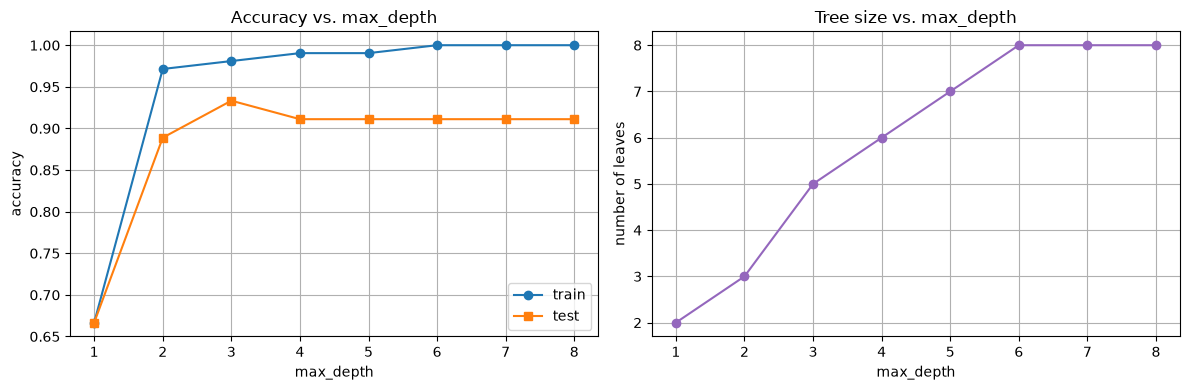

In [15]:
# ==== Hyperparameters (feel free to change!) ====
sweep_depth_min = 1          # @param {type:"slider", min:1, max:5} smallest max_depth to try
sweep_depth_max = 8          # @param {type:"slider", min:2, max:15} largest max_depth to try, larger = slower
sweep_min_samples_split = 2  # @param {type:"slider", min:2, max:30} nodes with fewer training flowers than this become leaves
sweep_min_gain = 1e-6        # @param {type:"number"} a split must gain more than this many bits, try 0.0-0.3
# ================================================

# All the max_depth values we will try (at least one, even if the range is reversed)
depths = list(range(sweep_depth_min, max(sweep_depth_min, sweep_depth_max) + 1))

train_accs, test_accs, leaf_counts, actual_depths = [], [], [], []
for d in depths:
    # Grow a fresh tree with this depth limit (Step 6)
    tree_d = fit_tree(X_train, y_train, d, sweep_min_samples_split, sweep_min_gain)
    # Accuracy on seen and unseen flowers
    train_accs.append(compute_accuracy(y_train, predict(tree_d, X_train)))
    test_accs.append(compute_accuracy(y_test, predict(tree_d, X_test)))
    # How many boxes, and how deep the tree really went (it may stop early once leaves are pure)
    leaf_counts.append(count_leaves(tree_d))
    actual_depths.append(tree_depth(tree_d))

# Print the numbers behind the plots
print(f"{'max_depth':>9} | {'actual depth':>12} | {'leaves':>6} | {'train acc':>9} | {'test acc':>8}")
print('-' * 57)
for d, ad, nl, tr, te in zip(depths, actual_depths, leaf_counts, train_accs, test_accs):
    print(f'{d:>9} | {ad:>12} | {nl:>6} | {tr:>9.3f} | {te:>8.3f}')

# Left: train vs test accuracy. Right: how many leaves the tree grew
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(depths, train_accs, marker='o', label='train')
axes[0].plot(depths, test_accs, marker='s', label='test')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('accuracy')
axes[0].set_title('Accuracy vs. max_depth')
axes[0].legend()
axes[0].grid(True)
axes[1].plot(depths, leaf_counts, marker='o', color='tab:purple')
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('number of leaves')
axes[1].set_title('Tree size vs. max_depth')
axes[1].grid(True)
plt.tight_layout()
plt.show()

Let's read these curves.

- At **depth 1**, the tree asks only the setosa question. The *no* leaf holds versicolor and virginica 50/50. On that tie, `np.argmax` picks versicolor, so every virginica is wrong and accuracy sits around $2/3$.
- At **depth 2 or 3**, one or two petal questions separate most versicolor from most virginica, and test accuracy jumps up.
- Beyond that, **training accuracy keeps creeping up toward 100%** while the number of leaves grows. The extra leaves hold only a handful of training flowers each, so the tree is carving out special cases. Test accuracy stops improving and may even dip. This is the overfitting from Question 3.
- Eventually the curves go flat. Every leaf is already pure, so allowing more depth changes nothing, and the *actual* depth column stops growing.

With only 45 test flowers, each test mistake moves accuracy by about 2.2 percentage points. So don't over-read small wiggles.

### Seeing the boxes

A tree with 4 features is hard to picture. Let's refit using only petal length and petal width, so the feature space is a plane we can draw.

Every question "is $x_j \le t$?" is a vertical or horizontal cut, so the leaves are **axis-aligned rectangles**. We color every point of a $150 \times 150$ grid by the class our tree predicts, walking each grid point down with `predict_one`.

We draw two trees side by side: a shallow one and a deep one. Training flowers are dots and test flowers are crosses.

Shallow tree (max_depth = 2):
Is petal length <= 2.450?  (n=105, IG=0.918)
    yes -> predict setosa  (n=35, p=[1.00, 0.00, 0.00])
    no  -> Is petal width <= 1.550?  (n=70, IG=0.748)
        yes -> predict versicolor  (n=34, p=[0.00, 0.97, 0.03])
        no  -> predict virginica  (n=36, p=[0.00, 0.06, 0.94])


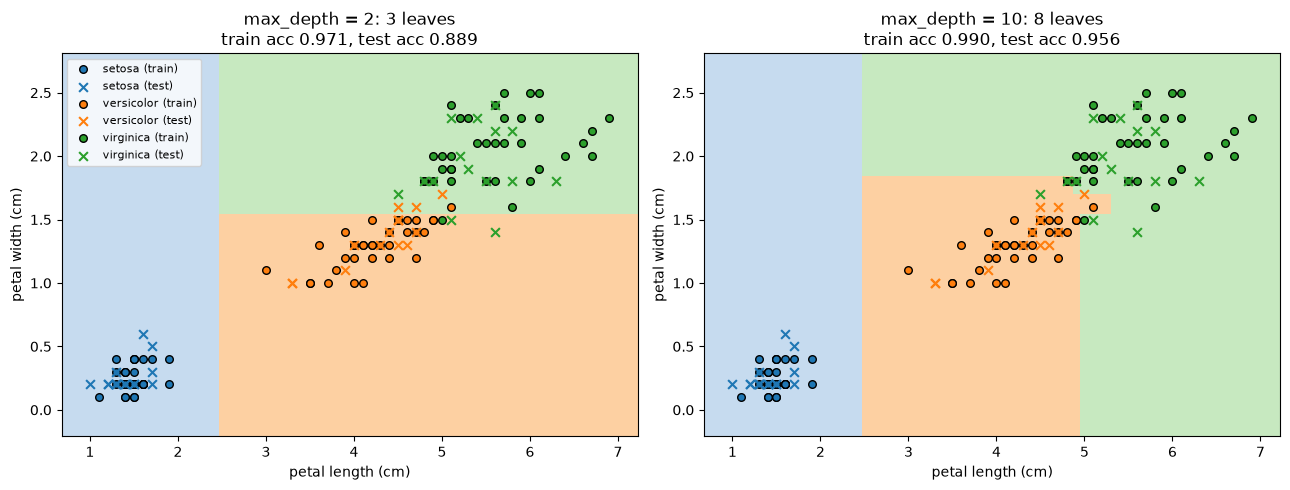

In [16]:
# ListedColormap lets us give each class its own pastel background color
from matplotlib.colors import ListedColormap

# ==== Hyperparameters (feel free to change!) ====
shallow_depth = 2             # @param {type:"slider", min:1, max:5} max_depth of the left (shallow) tree
deep_depth = 10               # @param {type:"slider", min:3, max:15} max_depth of the right (deep) tree
region_min_samples_split = 2  # @param {type:"slider", min:2, max:30} nodes with fewer training flowers than this become leaves
grid_resolution = 150         # @param {type:"slider", min:50, max:300} grid points per axis, more = sharper but slower
plot_margin = 0.3             # @param {type:"number"} empty space (cm) around the data, try 0.1-1.0
# ================================================

# Keep only petal length (index 2) and petal width (index 3)
petal_features = [2, 3]
X_train_2d = X_train[:, petal_features]
X_test_2d = X_test[:, petal_features]
petal_names = [feature_names[j] for j in petal_features]

# A grid covering every flower plus a margin
x_lo, x_hi = X_iris[:, 2].min() - plot_margin, X_iris[:, 2].max() + plot_margin
y_lo, y_hi = X_iris[:, 3].min() - plot_margin, X_iris[:, 3].max() + plot_margin
xs = np.linspace(x_lo, x_hi, grid_resolution)
ys = np.linspace(y_lo, y_hi, grid_resolution)
grid_x, grid_y = np.meshgrid(xs, ys)
# One row per grid point: (petal length, petal width)
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

# Strong colors for the flowers, pastel versions for the regions
point_colors = ['tab:blue', 'tab:orange', 'tab:green']
region_cmap = ListedColormap(['#c6dbef', '#fdd0a2', '#c7e9c0'])
n_species = len(class_names)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for panel, (ax, depth) in enumerate(zip(axes, [shallow_depth, deep_depth])):
    # Grow a tree on the two petal features only (Step 6)
    tree_2d = fit_tree(X_train_2d, y_train, max_depth=depth, min_samples_split=region_min_samples_split)
    # Print the shallow tree so we can match each question to a cut in the plot
    if panel == 0:
        print(f'Shallow tree (max_depth = {depth}):')
        print_tree(tree_2d, petal_names, class_names)
    # Walk every grid point down the tree (Step 7) and reshape back into the grid
    grid_pred = np.array([predict_one(tree_2d, point) for point in grid_points]).reshape(grid_x.shape)
    # Color each grid cell by its predicted class: the leaves show up as rectangles
    ax.pcolormesh(grid_x, grid_y, grid_pred, cmap=region_cmap, vmin=0, vmax=n_species - 1, shading='auto')
    # Draw the flowers on top: dots for training, crosses for test
    for k in range(n_species):
        ax.scatter(X_train_2d[y_train == k, 0], X_train_2d[y_train == k, 1], color=point_colors[k],
                   edgecolor='k', s=30, label=f'{class_names[k]} (train)')
        ax.scatter(X_test_2d[y_test == k, 0], X_test_2d[y_test == k, 1], color=point_colors[k],
                   marker='x', s=40, label=f'{class_names[k]} (test)')
    # Accuracy of this 2-feature tree on seen and unseen flowers
    train_acc_2d = compute_accuracy(y_train, predict(tree_2d, X_train_2d))
    test_acc_2d = compute_accuracy(y_test, predict(tree_2d, X_test_2d))
    ax.set_title(f'max_depth = {depth}: {count_leaves(tree_2d)} leaves\n'
                 f'train acc {train_acc_2d:.3f}, test acc {test_acc_2d:.3f}')
    ax.set_xlabel(f'{petal_names[0]} (cm)')
    ax.set_ylabel(f'{petal_names[1]} (cm)')

# One legend is enough for both panels
axes[0].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

Look at the left panel first: a few big rectangles. One cut gives setosa its own region, then one more cut splits the rest into versicolor and virginica. You can match each printed question to a vertical or horizontal edge in the picture. This is the "staircase of axis-aligned cuts" from Question 4.

Compare this with our earlier demos. Logistic regression would draw a single straight line at any angle, and Gaussian Naive Bayes would draw smooth curves around Gaussian blobs.

Now the right panel. Where versicolor and virginica overlap, the deep tree cuts thin slivers and tiny boxes, sometimes just to catch one or two training flowers. Training accuracy goes up, but those slivers are unlikely to mean anything for new flowers. This is what memorizing looks like in a picture.

## Experiment

Feel free to play around! Here are a few things worth trying:

1. **Depth on the full tree.** Set `iris_max_depth` to 1, then 2, then 6, and rerun the tree cells.
   - At depth 1, the *no* leaf holds versicolor and virginica 50/50 (look at its `p=[...]`).
   - At depth 6, the printed tree sprouts questions whose leaves have `n=1` or `n=2`. Those are memorized special cases. Does test accuracy actually improve?
2. **A different brake.** Keep `deep_depth = 10`, but raise `region_min_samples_split` to 10 or 20. Do the slivers in the right panel disappear, and what happens to test accuracy? You can also set `iris_min_gain` to 0.1 in the tree cell. Depth is not the only way to stop a tree from memorizing.
3. **A different split.** Change `split_seed` and rerun everything. The root question barely moves, but the deeper questions and the test accuracy can change noticeably. When small changes in the data produce quite different trees, that is a known weakness of single trees.

## Wrapping up

That's it! Starting from a hand-computed table of entropies, we built a decision tree from scratch:
- entropy to measure how mixed a node is,
- information gain to score a question,
- a brute-force search over midpoints,
- and a greedy recursion with a few stopping rules.

On Iris, it found the same setosa split we predicted by hand. It also gave us a model we can read line by line, and it showed us in a picture what overfitting looks like. No magic, just counting, a logarithm and some careful bookkeeping.

Thanks for following along! A natural next step is to grow *many* trees on reshuffled versions of the data and let them vote. That tames exactly the instability we saw in the last experiment.